<a href="https://colab.research.google.com/github/Vijayragav-V/SlickNet/blob/main/notebooks/SlickNetv1_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DRIVE = Path("/content/drive/MyDrive/SlickNet")

DATA_ROOT = PROJECT_DRIVE / "oilspill-data"
MODEL_DIR = PROJECT_DRIVE / "models"
RESULTS_DIR = PROJECT_DRIVE / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_ROOT)
print("Models:", MODEL_DIR)
print("Results:", RESULTS_DIR)

Dataset: /content/drive/MyDrive/SlickNet/oilspill-data
Models: /content/drive/MyDrive/SlickNet/models
Results: /content/drive/MyDrive/SlickNet/results


In [ ]:
import json
import random
import time

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
Tesla T4


In [ ]:
!apt-get -qq update
!apt-get -qq install git-lfs

!git lfs install

!git clone \
https://github.com/Garcia-INPE/oilspill-detection-dataset.git \
"/content/drive/MyDrive/SlickNet/oilspill-data"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package git-lfs.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Git LFS initialized.
fatal: destination path '/content/drive/MyDrive/SlickNet/oilspill-data' already exists and is not an empty directory.


In [ ]:
%cd /content/drive/MyDrive/SlickNet/oilspill-data
!git lfs pull

/content/drive/MyDrive/SlickNet/oilspill-data


In [ ]:
from pathlib import Path

DATA_ROOT = Path(
    "/content/drive/MyDrive/SlickNet/oilspill-data"
)

print(
    "Dataset exists:",
    DATA_ROOT.exists()
)

print(
    "Train split exists:",
    (
        DATA_ROOT
        / "splits"
        / "train.csv"
    ).exists()
)

print(
    "Validation split exists:",
    (
        DATA_ROOT
        / "splits"
        / "val.csv"
    ).exists()
)

print(
    "Test split exists:",
    (
        DATA_ROOT
        / "splits"
        / "test.csv"
    ).exists()
)

Dataset exists: True
Train split exists: True
Validation split exists: True
Test split exists: True


In [ ]:
train_df = pd.read_csv(
    DATA_ROOT / "splits" / "train.csv"
)

val_df = pd.read_csv(
    DATA_ROOT / "splits" / "val.csv"
)

test_df = pd.read_csv(
    DATA_ROOT / "splits" / "test.csv"
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_df.head()

Train: 108
Validation: 43
Test: 22


,sample_id,image_path,mask_path,classe,subclasse
0,IMG_01_TILE_001,IMAGES/IMG-RGB/IMG_01_TILE_001.png,IMAGES/LABELS-1D/IMG_01_TILE_001_1D.png,NaN,NaN
1,IMG_01_TILE_002,IMAGES/IMG-RGB/IMG_01_TILE_002.png,IMAGES/LABELS-1D/IMG_01_TILE_002_1D.png,NaN,NaN
2,IMG_02_TILE_001,IMAGES/IMG-RGB/IMG_02_TILE_001.png,IMAGES/LABELS-1D/IMG_02_TILE_001_1D.png,NaN,NaN
3,IMG_02_TILE_002,IMAGES/IMG-RGB/IMG_02_TILE_002.png,IMAGES/LABELS-1D/IMG_02_TILE_002_1D.png,NaN,NaN
4,IMG_02_TILE_003,IMAGES/IMG-RGB/IMG_02_TILE_003.png,IMAGES/LABELS-1D/IMG_02_TILE_003_1D.png,NaN,NaN


In [ ]:
sample_mask_path = (
    DATA_ROOT
    / train_df.iloc[0]["mask_path"]
)

sample_mask = np.array(
    Image.open(sample_mask_path).convert("L")
)

print("Mask shape:", sample_mask.shape)
print("Unique values:", np.unique(sample_mask))

Mask shape: (600, 800)
Unique values: [0 2]


In [ ]:
class OilSpillPatchDataset(Dataset):

    def __init__(
        self,
        dataframe,
        root,
        patch_size=256,
        samples_per_epoch=600,
        positive_fraction=0.70,
        augment=True
    ):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(root)

        self.patch_size = patch_size
        self.samples_per_epoch = samples_per_epoch
        self.positive_fraction = positive_fraction
        self.augment = augment

    def __len__(self):
        return self.samples_per_epoch

    def _load_pair(self, row):

        image = Image.open(
            self.root / row["image_path"]
        ).convert("RGB")

        mask = Image.open(
            self.root / row["mask_path"]
        ).convert("L")

        return image, mask

    def _ensure_large_enough(
        self,
        image,
        mask
    ):

        width, height = image.size

        minimum = self.patch_size

        if width >= minimum and height >= minimum:
            return image, mask

        scale = max(
            minimum / width,
            minimum / height
        )

        new_width = int(
            np.ceil(width * scale)
        )

        new_height = int(
            np.ceil(height * scale)
        )

        image = TF.resize(
            image,
            [new_height, new_width],
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask,
            [new_height, new_width],
            interpolation=InterpolationMode.NEAREST
        )

        return image, mask

    def _positive_crop_location(
        self,
        mask_array
    ):

        ys, xs = np.where(
            mask_array > 0
        )

        if len(xs) == 0:
            return None

        choice = random.randrange(
            len(xs)
        )

        center_x = int(xs[choice])
        center_y = int(ys[choice])

        jitter = self.patch_size // 4

        center_x += random.randint(
            -jitter,
            jitter
        )

        center_y += random.randint(
            -jitter,
            jitter
        )

        height, width = mask_array.shape

        left = (
            center_x
            - self.patch_size // 2
        )

        top = (
            center_y
            - self.patch_size // 2
        )

        left = max(
            0,
            min(
                left,
                width - self.patch_size
            )
        )

        top = max(
            0,
            min(
                top,
                height - self.patch_size
            )
        )

        return left, top

    def _negative_crop_location(
        self,
        mask_array
    ):

        height, width = mask_array.shape

        best_location = None
        best_positive_pixels = float("inf")

        for _ in range(25):

            left = random.randint(
                0,
                width - self.patch_size
            )

            top = random.randint(
                0,
                height - self.patch_size
            )

            crop = mask_array[
                top:top + self.patch_size,
                left:left + self.patch_size
            ]

            positive_pixels = int(
                (crop > 0).sum()
            )

            if positive_pixels == 0:
                return left, top

            if positive_pixels < best_positive_pixels:

                best_positive_pixels = positive_pixels
                best_location = (left, top)

        return best_location

    def _augment_pair(
        self,
        image,
        mask
    ):

        if random.random() < 0.5:

            image = TF.hflip(image)
            mask = TF.hflip(mask)

        if random.random() < 0.5:

            image = TF.vflip(image)
            mask = TF.vflip(mask)

        rotation_k = random.randint(
            0,
            3
        )

        if rotation_k > 0:

            angle = rotation_k * 90

            image = TF.rotate(
                image,
                angle,
                interpolation=InterpolationMode.BILINEAR
            )

            mask = TF.rotate(
                mask,
                angle,
                interpolation=InterpolationMode.NEAREST
            )

        if random.random() < 0.30:

            brightness_factor = random.uniform(
                0.90,
                1.10
            )

            image = TF.adjust_brightness(
                image,
                brightness_factor
            )

        if random.random() < 0.30:

            contrast_factor = random.uniform(
                0.90,
                1.10
            )

            image = TF.adjust_contrast(
                image,
                contrast_factor
            )

        return image, mask

    def __getitem__(
        self,
        index
    ):

        random_index = random.randrange(
            len(self.df)
        )

        row = self.df.iloc[
            random_index
        ]

        image, mask = self._load_pair(
            row
        )

        image, mask = self._ensure_large_enough(
            image,
            mask
        )

        mask_array = np.array(
            mask
        )

        wants_positive = (
            random.random()
            < self.positive_fraction
        )

        has_positive = np.any(
            mask_array > 0
        )

        if wants_positive and has_positive:

            location = self._positive_crop_location(
                mask_array
            )

        else:

            location = self._negative_crop_location(
                mask_array
            )

        left, top = location

        right = left + self.patch_size
        bottom = top + self.patch_size

        image = image.crop(
            (
                left,
                top,
                right,
                bottom
            )
        )

        mask = mask.crop(
            (
                left,
                top,
                right,
                bottom
            )
        )

        if self.augment:

            image, mask = self._augment_pair(
                image,
                mask
            )

        image = TF.to_tensor(
            image
        )

        if random.random() < 0.25:

            noise = (
                torch.randn_like(image)
                * 0.02
            )

            image = torch.clamp(
                image + noise,
                0.0,
                1.0
            )

        mask = np.array(
            mask
        )

        mask = (
            mask > 0
        ).astype(
            np.float32
        )

        mask = (
            torch
            .from_numpy(mask)
            .unsqueeze(0)
        )

        return image, mask

In [ ]:
class OilSpillFullSceneDataset(Dataset):

    def __init__(
        self,
        dataframe,
        root,
        size=(384, 512)
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.root = Path(root)
        self.size = size

    def __len__(self):
        return len(self.df)

    def __getitem__(
        self,
        index
    ):

        row = self.df.iloc[index]

        image = Image.open(
            self.root / row["image_path"]
        ).convert("RGB")

        mask = Image.open(
            self.root / row["mask_path"]
        ).convert("L")

        image = TF.resize(
            image,
            self.size,
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask,
            self.size,
            interpolation=InterpolationMode.NEAREST
        )

        image = TF.to_tensor(
            image
        )

        mask = np.array(
            mask
        )

        mask = (
            mask > 0
        ).astype(
            np.float32
        )

        mask = (
            torch
            .from_numpy(mask)
            .unsqueeze(0)
        )

        return image, mask

In [ ]:
PATCH_SIZE = 256
SAMPLES_PER_EPOCH = 600
POSITIVE_FRACTION = 0.70

train_dataset = OilSpillPatchDataset(
    train_df,
    DATA_ROOT,
    patch_size=PATCH_SIZE,
    samples_per_epoch=SAMPLES_PER_EPOCH,
    positive_fraction=POSITIVE_FRACTION,
    augment=True
)

val_dataset = OilSpillFullSceneDataset(
    val_df,
    DATA_ROOT,
    size=(384, 512)
)

print(
    "Training samples per epoch:",
    len(train_dataset)
)

print(
    "Validation images:",
    len(val_dataset)
)

Training samples per epoch: 600
Validation images: 43


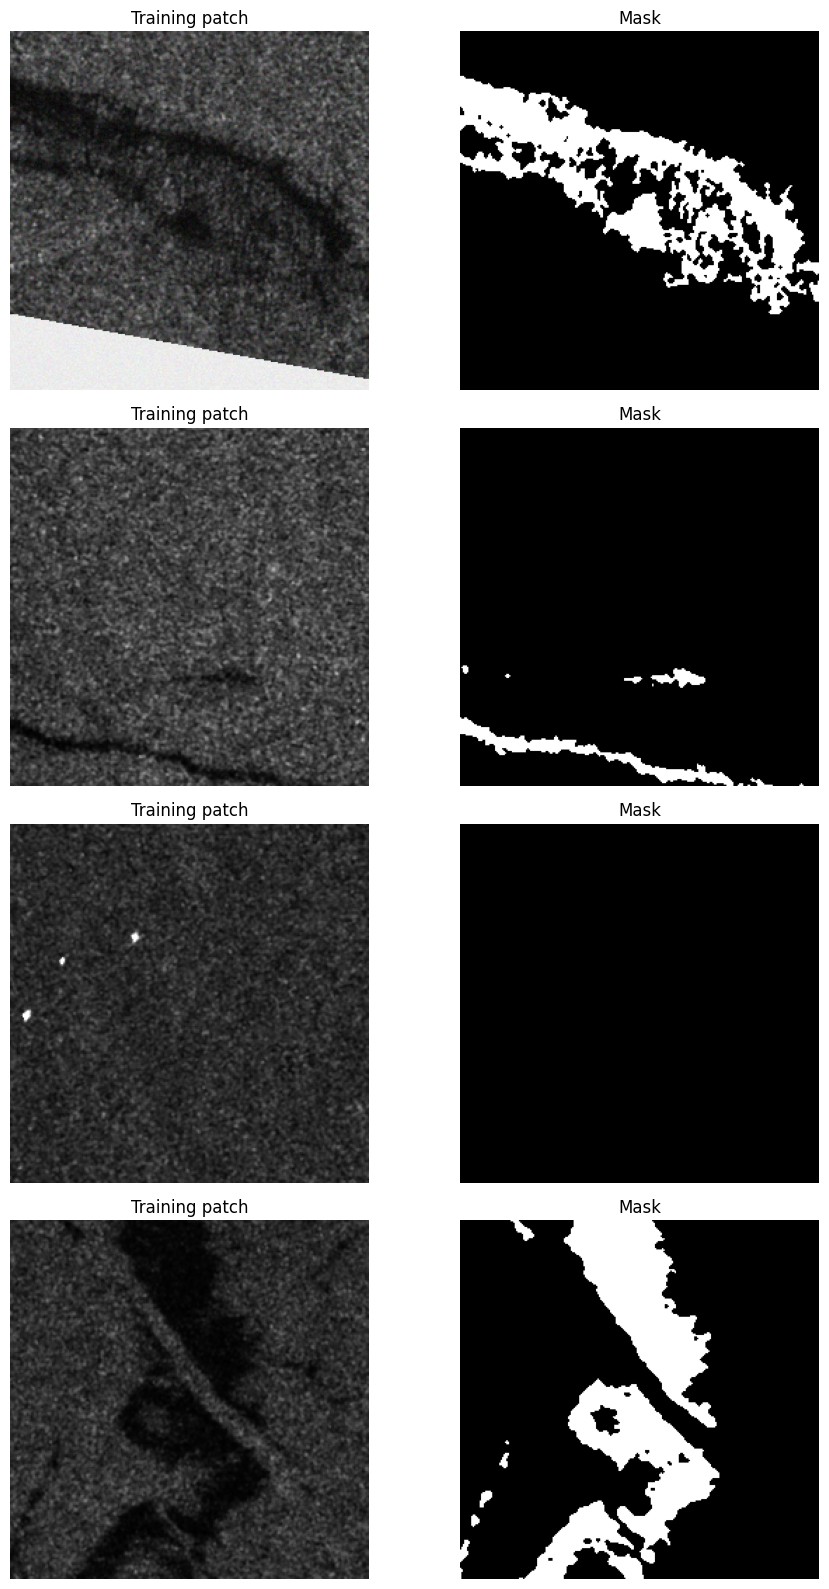

In [ ]:
fig, axes = plt.subplots(
    4,
    2,
    figsize=(10, 16)
)

for row in range(4):

    image, mask = train_dataset[row]

    image_np = (
        image
        .permute(1, 2, 0)
        .numpy()
    )

    mask_np = mask[0].numpy()

    axes[row, 0].imshow(
        image_np
    )

    axes[row, 0].set_title(
        "Training patch"
    )

    axes[row, 0].axis(
        "off"
    )

    axes[row, 1].imshow(
        mask_np,
        cmap="gray"
    )

    axes[row, 1].set_title(
        "Mask"
    )

    axes[row, 1].axis(
        "off"
    )

plt.tight_layout()
plt.show()

In [ ]:
positive_patch_count = 0
total = 200

for i in range(total):

    _, mask = train_dataset[i]

    if mask.sum() > 0:
        positive_patch_count += 1

print(
    "Positive patches:",
    positive_patch_count,
    "/",
    total
)

print(
    "Observed fraction:",
    positive_patch_count / total
)

Positive patches: 149 / 200
Observed fraction: 0.745


In [ ]:
BATCH_SIZE = 8
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

Train batches: 75
Validation batches: 22


In [ ]:
class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )

    def forward(
        self,
        x
    ):

        return self.block(x)


class UNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):

        super().__init__()

        self.pool = nn.MaxPool2d(
            2
        )

        self.enc1 = DoubleConv(
            in_channels,
            16
        )

        self.enc2 = DoubleConv(
            16,
            32
        )

        self.enc3 = DoubleConv(
            32,
            64
        )

        self.enc4 = DoubleConv(
            64,
            128
        )

        self.bottleneck = DoubleConv(
            128,
            256
        )

        self.up4 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            256,
            128
        )

        self.up3 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            128,
            64
        )

        self.up2 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            64,
            32
        )

        self.up1 = nn.ConvTranspose2d(
            32,
            16,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            32,
            16
        )

        self.output = nn.Conv2d(
            16,
            out_channels,
            kernel_size=1
        )

    def forward(
        self,
        x
    ):

        e1 = self.enc1(
            x
        )

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        b = self.bottleneck(
            self.pool(e4)
        )

        d4 = self.up4(
            b
        )

        d4 = torch.cat(
            [d4, e4],
            dim=1
        )

        d4 = self.dec4(
            d4
        )

        d3 = self.up3(
            d4
        )

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(
            d3
        )

        d2 = self.up2(
            d3
        )

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(
            d2
        )

        d1 = self.up1(
            d2
        )

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(
            d1
        )

        return self.output(
            d1
        )

In [ ]:
model = UNet(
    in_channels=3,
    out_channels=1
)

model = model.to(
    device
)

print("Model created.")

Model created.


In [ ]:
bce_loss = nn.BCEWithLogitsLoss()

In [ ]:
def tversky_loss(
    logits,
    targets,
    alpha=0.30,
    beta=0.70,
    smooth=1.0
):

    probabilities = torch.sigmoid(
        logits
    )

    dims = (
        1,
        2,
        3
    )

    true_positive = (
        probabilities
        * targets
    ).sum(
        dim=dims
    )

    false_positive = (
        probabilities
        * (1 - targets)
    ).sum(
        dim=dims
    )

    false_negative = (
        (1 - probabilities)
        * targets
    ).sum(
        dim=dims
    )

    tversky = (
        true_positive
        + smooth
    ) / (
        true_positive
        + alpha * false_positive
        + beta * false_negative
        + smooth
    )

    return 1 - tversky.mean()

In [ ]:
def combined_loss(
    logits,
    targets
):

    bce = bce_loss(
        logits,
        targets
    )

    tversky = tversky_loss(
        logits,
        targets
    )

    loss = (
        0.40 * bce
        + 0.60 * tversky
    )

    return loss

In [ ]:
def calculate_binary_counts(
    logits,
    targets,
    threshold=0.50
):

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities
        >= threshold
    )

    targets_bool = (
        targets
        >= 0.5
    )

    tp = torch.logical_and(
        predictions,
        targets_bool
    ).sum().item()

    fp = torch.logical_and(
        predictions,
        torch.logical_not(
            targets_bool
        )
    ).sum().item()

    fn = torch.logical_and(
        torch.logical_not(
            predictions
        ),
        targets_bool
    ).sum().item()

    tn = torch.logical_and(
        torch.logical_not(
            predictions
        ),
        torch.logical_not(
            targets_bool
        )
    ).sum().item()

    return tp, fp, fn, tn

In [ ]:
def counts_to_metrics(
    tp,
    fp,
    fn,
    tn
):

    epsilon = 1e-8

    iou = (
        tp
        /
        (
            tp
            + fp
            + fn
            + epsilon
        )
    )

    dice = (
        2 * tp
        /
        (
            2 * tp
            + fp
            + fn
            + epsilon
        )
    )

    precision = (
        tp
        /
        (
            tp
            + fp
            + epsilon
        )
    )

    recall = (
        tp
        /
        (
            tp
            + fn
            + epsilon
        )
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall)
    }

In [ ]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            images
        )

        loss = combined_loss(
            logits,
            masks
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item()
            * images.size(0)
        )

        tp, fp, fn, tn = (
            calculate_binary_counts(
                logits.detach(),
                masks,
                threshold=0.50
            )
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn

    average_loss = (
        total_loss
        / len(loader.dataset)
    )

    metrics = counts_to_metrics(
        total_tp,
        total_fp,
        total_fn,
        total_tn
    )

    return average_loss, metrics

In [ ]:
@torch.no_grad()
def validate(
    model,
    loader,
    device
):

    model.eval()

    total_loss = 0.0

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = model(
            images
        )

        loss = combined_loss(
            logits,
            masks
        )

        total_loss += (
            loss.item()
            * images.size(0)
        )

        tp, fp, fn, tn = (
            calculate_binary_counts(
                logits,
                masks,
                threshold=0.50
            )
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn

    average_loss = (
        total_loss
        / len(loader.dataset)
    )

    metrics = counts_to_metrics(
        total_tp,
        total_fp,
        total_fn,
        total_tn
    )

    return average_loss, metrics

In [ ]:
LEARNING_RATE = 3e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.0001
)


In [ ]:
scheduler = (
    torch.optim.lr_scheduler
    .ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
)

In [ ]:
history = {
    "train_loss": [],
    "val_loss": [],

    "train_iou": [],
    "val_iou": [],

    "train_dice": [],
    "val_dice": [],

    "train_precision": [],
    "val_precision": [],

    "train_recall": [],
    "val_recall": [],

    "learning_rate": []
}

In [ ]:
MODEL_PATH = (
    MODEL_DIR
    / "slicknet_v1_1_patch_tversky.pth"
)

print("Checkpoint path:")
print(MODEL_PATH)

Checkpoint path:
/content/drive/MyDrive/SlickNet/models/slicknet_v1_1_patch_tversky.pth


In [ ]:
EPOCHS = 40
EARLY_STOPPING_PATIENCE = 8

best_iou = -1.0
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss, train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    val_loss, val_metrics = validate(
        model,
        val_loader,
        device
    )

    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["train_iou"].append(
        train_metrics["iou"]
    )

    history["val_iou"].append(
        val_metrics["iou"]
    )

    history["train_dice"].append(
        train_metrics["dice"]
    )

    history["val_dice"].append(
        val_metrics["dice"]
    )

    history["train_precision"].append(
        train_metrics["precision"]
    )

    history["val_precision"].append(
        val_metrics["precision"]
    )

    history["train_recall"].append(
        train_metrics["recall"]
    )

    history["val_recall"].append(
        val_metrics["recall"]
    )

    history["learning_rate"].append(
        current_lr
    )

    elapsed = (
        time.time()
        - start_time
    )

    print(
        f"Epoch {epoch + 1:02d} | "
        f"{elapsed:.1f}s | "
        f"LR {current_lr:.6f}"
    )

    print(
        f"  Train | "
        f"Loss {train_loss:.4f} | "
        f"IoU {train_metrics['iou']:.4f} | "
        f"Dice {train_metrics['dice']:.4f} | "
        f"P {train_metrics['precision']:.4f} | "
        f"R {train_metrics['recall']:.4f}"
    )

    print(
        f"  Val   | "
        f"Loss {val_loss:.4f} | "
        f"IoU {val_metrics['iou']:.4f} | "
        f"Dice {val_metrics['dice']:.4f} | "
        f"P {val_metrics['precision']:.4f} | "
        f"R {val_metrics['recall']:.4f}"
    )

    scheduler.step(
        val_metrics["iou"]
    )

    if val_metrics["iou"] > best_iou:

        best_iou = val_metrics["iou"]

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_iou": best_iou,
                "val_dice": val_metrics["dice"],
                "val_precision": val_metrics["precision"],
                "val_recall": val_metrics["recall"],
                "patch_size": PATCH_SIZE,
                "positive_fraction": POSITIVE_FRACTION,
                "validation_size": [384, 512],
                "learning_rate": current_lr
            },
            MODEL_PATH
        )

        print(
            "  ✓ Saved new best model."
        )

    else:

        epochs_without_improvement += 1

        print(
            "  No improvement:",
            epochs_without_improvement,
            "/",
            EARLY_STOPPING_PATIENCE
        )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "Early stopping triggered."
        )

        break

Epoch 01 | 44.1s | LR 0.000300
  Train | Loss 0.7431 | IoU 0.1984 | Dice 0.3311 | P 0.2026 | R 0.9058
  Val   | Loss 0.7260 | IoU 0.4570 | Dice 0.6273 | P 0.4660 | R 0.9595
  ✓ Saved new best model.
Epoch 02 | 14.4s | LR 0.000300
  Train | Loss 0.6789 | IoU 0.4952 | Dice 0.6624 | P 0.5355 | R 0.8680
  Val   | Loss 0.7587 | IoU 0.1448 | Dice 0.2530 | P 0.1454 | R 0.9728
  No improvement: 1 / 8
Epoch 03 | 14.2s | LR 0.000300
  Train | Loss 0.6562 | IoU 0.5457 | Dice 0.7061 | P 0.5787 | R 0.9055
  Val   | Loss 0.6791 | IoU 0.3411 | Dice 0.5087 | P 0.3479 | R 0.9453
  No improvement: 2 / 8
Epoch 04 | 14.5s | LR 0.000300
  Train | Loss 0.6225 | IoU 0.5677 | Dice 0.7242 | P 0.6084 | R 0.8946
  Val   | Loss 0.6524 | IoU 0.3861 | Dice 0.5571 | P 0.3946 | R 0.9472
  No improvement: 3 / 8
Epoch 05 | 14.6s | LR 0.000300
  Train | Loss 0.5987 | IoU 0.5718 | Dice 0.7276 | P 0.6232 | R 0.8740
  Val   | Loss 0.6125 | IoU 0.5066 | Dice 0.6725 | P 0.5256 | R 0.9337
  ✓ Saved new best model.
Epoch 06 | 

In [ ]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print("Saved validation IoU:", checkpoint["val_iou"])
print("Saved validation Dice:", checkpoint["val_dice"])
print("Saved validation Precision:", checkpoint["val_precision"])
print("Saved validation Recall:", checkpoint["val_recall"])

Loaded epoch: 26
Saved validation IoU: 0.7423919167636727
Saved validation Dice: 0.8521526180431267
Saved validation Precision: 0.8262040021235071
Saved validation Recall: 0.8797840234315489


In [ ]:
history_df = pd.DataFrame(history)

HISTORY_PATH = (
    RESULTS_DIR
    / "slicknet_v1_1_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

history_df.tail()

,train_loss,val_loss,train_iou,val_iou,train_dice,val_dice,train_precision,val_precision,train_recall,val_recall,learning_rate
29,0.324838,0.369645,0.727956,0.424105,0.842563,0.595609,0.799188,0.443845,0.890917,0.905085,0.000075
30,0.329854,0.348557,0.741411,0.515811,0.851506,0.680574,0.816037,0.539904,0.890198,0.920375,0.000037
31,0.318597,0.324446,0.717857,0.659257,0.835759,0.794641,0.789749,0.699037,0.887461,0.920540,0.000037
32,0.335904,0.343486,0.730990,0.497603,0.844592,0.664533,0.796535,0.517040,0.898820,0.929759,0.000037
33,0.318687,0.326681,0.735378,0.650524,0.847514,0.788263,0.809139,0.687353,0.889709,0.923901,0.000037


In [ ]:
@torch.no_grad()
def collect_predictions(
    model,
    loader,
    device
):

    model.eval()

    all_probabilities = []
    all_targets = []

    for images, masks in loader:

        images = images.to(
            device
        )

        logits = model(
            images
        )

        probabilities = torch.sigmoid(
            logits
        )

        all_probabilities.append(
            probabilities.cpu()
        )

        all_targets.append(
            masks.cpu()
        )

    return (
        torch.cat(
            all_probabilities,
            dim=0
        ),
        torch.cat(
            all_targets,
            dim=0
        )
    )

In [ ]:
val_probs, val_targets = collect_predictions(
    model,
    val_loader,
    device
)

print("Probabilities:", val_probs.shape)
print("Targets:", val_targets.shape)

Probabilities: torch.Size([43, 1, 384, 512])
Targets: torch.Size([43, 1, 384, 512])


In [ ]:
def remove_small_components(
    binary_mask,
    min_pixels=0
):

    binary_mask = binary_mask.astype(
        np.uint8
    )

    if min_pixels <= 0:
        return binary_mask

    (
        num_labels,
        labels,
        stats,
        _
    ) = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    cleaned = np.zeros_like(
        binary_mask,
        dtype=np.uint8
    )

    for label_id in range(
        1,
        num_labels
    ):

        area = stats[
            label_id,
            cv2.CC_STAT_AREA
        ]

        if area >= min_pixels:

            cleaned[
                labels == label_id
            ] = 1

    return cleaned

In [ ]:
def evaluate_predictions(
    probabilities,
    targets,
    threshold,
    min_pixels
):

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    image_ious = []
    image_dices = []

    for i in range(
        probabilities.shape[0]
    ):

        probability_map = (
            probabilities[i, 0]
            .numpy()
        )

        target = (
            targets[i, 0]
            .numpy()
            >= 0.5
        )

        prediction = (
            probability_map
            >= threshold
        ).astype(
            np.uint8
        )

        prediction = remove_small_components(
            prediction,
            min_pixels
        )

        pred_bool = (
            prediction > 0
        )

        target_bool = target

        tp = np.logical_and(
            pred_bool,
            target_bool
        ).sum()

        fp = np.logical_and(
            pred_bool,
            np.logical_not(target_bool)
        ).sum()

        fn = np.logical_and(
            np.logical_not(pred_bool),
            target_bool
        ).sum()

        tn = np.logical_and(
            np.logical_not(pred_bool),
            np.logical_not(target_bool)
        ).sum()

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn

        iou_denominator = (
            tp + fp + fn
        )

        dice_denominator = (
            2 * tp + fp + fn
        )

        if iou_denominator == 0:
            image_iou = 1.0
        else:
            image_iou = (
                tp / iou_denominator
            )

        if dice_denominator == 0:
            image_dice = 1.0
        else:
            image_dice = (
                2 * tp
                / dice_denominator
            )

        image_ious.append(
            image_iou
        )

        image_dices.append(
            image_dice
        )

    epsilon = 1e-8

    global_iou = (
        total_tp
        /
        (
            total_tp
            + total_fp
            + total_fn
            + epsilon
        )
    )

    global_dice = (
        2 * total_tp
        /
        (
            2 * total_tp
            + total_fp
            + total_fn
            + epsilon
        )
    )

    precision = (
        total_tp
        /
        (
            total_tp
            + total_fp
            + epsilon
        )
    )

    recall = (
        total_tp
        /
        (
            total_tp
            + total_fn
            + epsilon
        )
    )

    return {
        "global_iou": float(global_iou),
        "global_dice": float(global_dice),
        "precision": float(precision),
        "recall": float(recall),
        "mean_image_iou": float(
            np.mean(image_ious)
        ),
        "mean_image_dice": float(
            np.mean(image_dices)
        ),
        "tp": int(total_tp),
        "fp": int(total_fp),
        "fn": int(total_fn),
        "tn": int(total_tn)
    }

In [ ]:
thresholds = np.round(
    np.arange(
        0.15,
        0.81,
        0.05
    ),
    2
)

min_pixel_options = [
    0,
    25,
    50,
    100,
    200,
    400
]

tuning_results = []

for threshold in thresholds:

    for min_pixels in min_pixel_options:

        metrics = evaluate_predictions(
            val_probs,
            val_targets,
            threshold=threshold,
            min_pixels=min_pixels
        )

        tuning_results.append({
            "threshold": threshold,
            "min_pixels": min_pixels,
            **metrics
        })

tuning_df = pd.DataFrame(
    tuning_results
)

tuning_df = tuning_df.sort_values(
    "global_iou",
    ascending=False
)

tuning_df.head(15)

,threshold,min_pixels,global_iou,global_dice,precision,recall,mean_image_iou,mean_image_dice,tp,fp,fn,tn
66,0.70,0,0.748884,0.856413,0.862617,0.850299,0.616487,0.733766,191023,30423,33631,8199067
60,0.65,0,0.748179,0.855952,0.852539,0.859393,0.618626,0.736039,193066,33394,31588,8196096
72,0.75,0,0.747824,0.855720,0.874332,0.837884,0.612010,0.728729,188234,27055,36420,8202435
67,0.70,25,0.747369,0.855422,0.864899,0.846150,0.608812,0.725642,190091,29693,34563,8199797
61,0.65,25,0.747143,0.855274,0.854886,0.855662,0.612099,0.729253,192228,32630,32426,8196860
54,0.60,0,0.746804,0.855052,0.843471,0.866955,0.620036,0.737371,194765,36144,29889,8193346
55,0.60,25,0.746143,0.854618,0.846169,0.863239,0.612988,0.729971,193930,35256,30724,8194234
73,0.75,25,0.746015,0.854534,0.876457,0.833682,0.604207,0.721141,187290,26400,37364,8203090
48,0.55,0,0.744736,0.853695,0.834651,0.873628,0.621111,0.738173,196264,38881,28390,8190609
49,0.55,25,0.744217,0.853354,0.837712,0.869591,0.614454,0.731474,195357,37846,29297,8191644


In [ ]:
best_row = tuning_df.iloc[0]

BEST_THRESHOLD = float(
    best_row["threshold"]
)

BEST_MIN_PIXELS = int(
    best_row["min_pixels"]
)

print(
    "Best threshold:",
    BEST_THRESHOLD
)

print(
    "Best min pixels:",
    BEST_MIN_PIXELS
)

print(
    "Validation IoU:",
    best_row["global_iou"]
)

print(
    "Validation Dice:",
    best_row["global_dice"]
)

print(
    "Precision:",
    best_row["precision"]
)

print(
    "Recall:",
    best_row["recall"]
)

Best threshold: 0.7
Best min pixels: 0
Validation IoU: 0.7488836704210592
Validation Dice: 0.8564133602331123
Precision: 0.862616619853108
Recall: 0.8502986815280008


In [ ]:
TUNING_PATH = (
    RESULTS_DIR
    / "slicknet_v1_1_validation_tuning.csv"
)

tuning_df.to_csv(
    TUNING_PATH,
    index=False
)

print("Saved:", TUNING_PATH)

Saved: /content/drive/MyDrive/SlickNet/results/slicknet_v1_1_validation_tuning.csv


In [ ]:
test_dataset = OilSpillFullSceneDataset(
    test_df,
    DATA_ROOT,
    size=(384, 512)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test images: 22
Test batches: 11


In [ ]:
test_probs, test_targets = collect_predictions(
    model,
    test_loader,
    device
)

print("Probabilities:", test_probs.shape)
print("Targets:", test_targets.shape)

Probabilities: torch.Size([22, 1, 384, 512])
Targets: torch.Size([22, 1, 384, 512])


In [ ]:
test_metrics = evaluate_predictions(
    test_probs,
    test_targets,
    threshold=BEST_THRESHOLD,
    min_pixels=BEST_MIN_PIXELS
)

print("FINAL SLICKNET V1.1 TEST RESULTS")
print("--------------------------------")

print(
    f"IoU:        "
    f"{test_metrics['global_iou']:.4f}"
)

print(
    f"Dice:       "
    f"{test_metrics['global_dice']:.4f}"
)

print(
    f"Precision:  "
    f"{test_metrics['precision']:.4f}"
)

print(
    f"Recall:     "
    f"{test_metrics['recall']:.4f}"
)

print(
    f"Mean IoU:   "
    f"{test_metrics['mean_image_iou']:.4f}"
)

print(
    f"Mean Dice:  "
    f"{test_metrics['mean_image_dice']:.4f}"
)

print()
print(
    "TP:",
    test_metrics["tp"]
)

print(
    "FP:",
    test_metrics["fp"]
)

print(
    "FN:",
    test_metrics["fn"]
)

FINAL SLICKNET V1.1 TEST RESULTS
--------------------------------
IoU:        0.7422
Dice:       0.8520
Precision:  0.9117
Recall:     0.7997
Mean IoU:   0.5182
Mean Dice:  0.6538

TP: 37760
FP: 3658
FN: 9459


In [ ]:
TEST_METRICS_PATH = (
    RESULTS_DIR
    / "slicknet_v1_1_test_metrics.json"
)

with open(
    TEST_METRICS_PATH,
    "w"
) as f:

    json.dump(
        test_metrics,
        f,
        indent=4
    )

print("Saved:", TEST_METRICS_PATH)

Saved: /content/drive/MyDrive/SlickNet/results/slicknet_v1_1_test_metrics.json


In [ ]:
CONFIG = {
    "version": "1.1",

    "architecture":
        "custom_unet",

    "training_method":
        "positive_patch_oversampling",

    "patch_size":
        PATCH_SIZE,

    "positive_fraction":
        POSITIVE_FRACTION,

    "input_height":
        384,

    "input_width":
        512,

    "threshold":
        BEST_THRESHOLD,

    "min_pixels":
        BEST_MIN_PIXELS,

    "loss":
        "0.4_bce_plus_0.6_tversky",

    "tversky_alpha":
        0.30,

    "tversky_beta":
        0.70,

    "best_validation_iou":
        float(
            best_row["global_iou"]
        ),

    "best_validation_dice":
        float(
            best_row["global_dice"]
        )
}

CONFIG_PATH = (
    MODEL_DIR
    / "slicknet_v1_1_config.json"
)

with open(
    CONFIG_PATH,
    "w"
) as f:

    json.dump(
        CONFIG,
        f,
        indent=4
    )

print("Saved:", CONFIG_PATH)

Saved: /content/drive/MyDrive/SlickNet/models/slicknet_v1_1_config.json


In [ ]:
DEPLOY_MODEL_PATH = (
    MODEL_DIR
    / "slicknet_v1_1.pth"
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu"
)

torch.save(
    checkpoint["model_state_dict"],
    DEPLOY_MODEL_PATH
)

print("Saved deployment model:")
print(DEPLOY_MODEL_PATH)

Saved deployment model:
/content/drive/MyDrive/SlickNet/models/slicknet_v1_1.pth


In [ ]:
from google.colab import files

files.download(
    str(DEPLOY_MODEL_PATH)
)

files.download(
    str(CONFIG_PATH)
)

files.download(
    str(TEST_METRICS_PATH)
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>